In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## data Source:
https://www.pik-potsdam.de/~mmalte/rcps/

## cite
Meinshausen, M., S. J. Smith, K. V. Calvin, J. S. Daniel, M. L. T. Kainuma, J.-F. Lamarque, K. Matsumoto, S. A. Montzka, S. C. B. Raper, K. Riahi, A. M. Thomson, G. J. M. Velders and D. van Vuuren (2011). "The RCP Greenhouse Gas Concentrations and their Extension from 1765 to 2300." Climatic Change (Special Issue), DOI: 10.1007/s10584-011-0156-z [link](https://link.springer.com/article/10.1007/s10584-011-0156-z)

In [3]:
def gtC_to_gtCO2(gtC, factor=44.01/12.011):
    return gtC * factor


In [4]:
def get_CO2_total(df, rcp):
    df.columns = df.iloc[0]
    df = df[1:].reset_index(drop=True)
    df["YEARS"] = df["YEARS"].astype(int)
    df_sub = df[(df["YEARS"] >= 1940) & (df["YEARS"] <= 2100)].copy()
    # Spalten-Index 1 und 2 auswählen
    col1 = df.columns[1]
    col2 = df.columns[2]
    # Zu float konvertieren (in-place)
    df_sub[col1] = pd.to_numeric(df_sub[col1], errors="coerce")
    df_sub[col2] = pd.to_numeric(df_sub[col2], errors="coerce")
    df_sub[rcp] = gtC_to_gtCO2(df_sub[col1] + df_sub[col2])
    # Neues DataFrame mit YEARS als Index
    result = df_sub.set_index("YEARS")[[rcp]]
    return result


In [5]:
file_rcp85 = "RCP85_EMISSIONS.DAT"
file_rcp85 = "RCP85_EMISSIONS.DAT"
file_rcp26 = "RCP3PD_EMISSIONS.DAT"

rcp_files_dict = {}
rcp_files_dict['RCP8.5'] = ["RCP85_EMISSIONS.DAT", 30]
rcp_files_dict['RCP4.5'] = ["RCP45_EMISSIONS.DAT",31]
rcp_files_dict['RCP2.6'] = ["RCP3PD_EMISSIONS.DAT",31]
rcps = ['RCP8.5', 'RCP4.5', 'RCP2.6']
#rcps=["RCP4.5",]
#df_out=pd.DataFrame(columns=["YEARS", "RCP8.5", "RCP4.5", "RCP2.6"])
df_merged=pd.DataFrame()

In [7]:
df_merged

""


In [8]:
for rcp in rcps:
    df=pd.read_csv(rcp_files_dict[rcp][0], header=rcp_files_dict[rcp][1], sep=r"[ \t]{4,}", engine='python')
    df_merged = df_merged.join(get_CO2_total(df, rcp), how="outer")


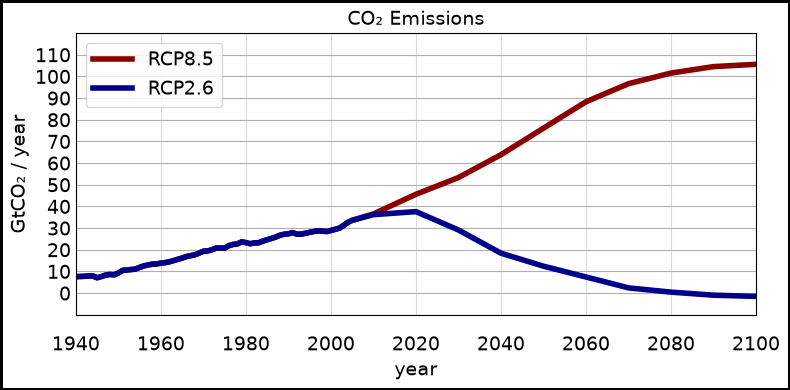

In [9]:

# create plot:

fig, ax = plt.subplots(figsize=(8, 4))

scenario_colors = {'rcp26': 'darkblue', 'rcp85': 'darkred'}

# Linien plotten
plt.plot(df_merged.index, df_merged['RCP8.5'], label='RCP8.5', linewidth=4, color=scenario_colors['rcp85'])
#plt.plot(df_merged.index, df_merged['RCP4.5'], label='wenig Klimaschutz (RCP4.5)', linewidth=4, color=middle)
plt.plot(df_merged.index, df_merged['RCP2.6'], label='RCP2.6', linewidth=4, color=scenario_colors['rcp26'])

# Achsenbeschriftungen
plt.xlabel("year", fontsize=14)
plt.ylabel("GtCO₂ / year", fontsize=14)

# Titel optional
# plt.title("Emissionen der RCP-Szenarien")
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
#ax.spines['bottom'].set_visible(False)
#ax.spines['left'].set_visible(False)

ax.yaxis.grid(True)      # horizontales Grid AN
# Achsengestaltung wie GERICS
plt.xlim(df_merged.index.min(), df_merged.index.max())
xticks = np.arange(df_merged.index.min(), df_merged.index.max()+20, 20)
ax.set_xticks(xticks)
ax.set_xticklabels([f"{v}" for v in xticks], fontsize=14)
ax.grid(axis='x', which='major', color='lightgray', linestyle='-', linewidth=0.8, alpha=0.8)
#plt.ylim(-20,110)
#yticks=np.arange(-20,110,10)
#yticks[0] = -15
#ax.set_yticks(yticks)
yticks = np.arange(-10, 121, 10)
ax.set_yticks(yticks)
yticklabels = [f"{v}" for v in yticks]
yticklabels[0]=''
yticklabels[0-1]=''
ax.set_yticklabels(yticklabels, fontsize=14)
# Legende oben
plt.legend(loc='upper left',fontsize=14)
plt.title("CO₂ Emissions", fontsize=14)
# Dezentes Layout
ax.tick_params(axis="both", length=0)
#ax.grid(alpha=0.3, linewidth=0.8)

#plt.grid(True, linestyle='--', alpha=0.4)
ax.tick_params(axis="x", pad=15)

plt.tight_layout()
fig.patch.set_edgecolor("black")
fig.patch.set_linewidth(2.5)
# Speichern oder anzeigen
plt.savefig("emissionen_rcp.png", dpi=1200)
plt.show()
